In [6]:
import pandas as pd

In [7]:
df=pd.read_csv('/content/price_data.csv')

In [8]:
print(df)

           date  avg_monthly_price
0    2005-01-01               5500
1    2005-02-01               5476
2    2005-03-01               5466
3    2005-04-01               5487
4    2005-05-01               5876
..          ...                ...
244  2025-05-01              14263
245  2025-06-01              14263
246  2025-07-01              16000
247  2025-08-01              15025
248  2025-09-01              15750

[249 rows x 2 columns]


In [9]:
print(df.shape)

(249, 2)


In [10]:
print(df.describe())

       avg_monthly_price
count         249.000000
mean         7918.891566
std          2804.992684
min          3500.000000
25%          6123.000000
50%          7250.000000
75%          9783.000000
max         16163.000000


In [11]:
print(df.head())

         date  avg_monthly_price
0  2005-01-01               5500
1  2005-02-01               5476
2  2005-03-01               5466
3  2005-04-01               5487
4  2005-05-01               5876


In [12]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   date               249 non-null    object
 1   avg_monthly_price  249 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 4.0+ KB
None


In [13]:
print(df.isnull())

      date  avg_monthly_price
0    False              False
1    False              False
2    False              False
3    False              False
4    False              False
..     ...                ...
244  False              False
245  False              False
246  False              False
247  False              False
248  False              False

[249 rows x 2 columns]


In [14]:
print(df.isnull().sum())

date                 0
avg_monthly_price    0
dtype: int64


In [15]:
df["date"] = pd.to_datetime(
    df["date"],
    format="%Y-%m-%d",
    errors="coerce"
)

In [16]:
df = df.dropna(
    subset=["date", "avg_monthly_price"]
)

In [17]:
df = df.sort_values("date").reset_index(drop=True)

In [18]:
print(df.dtypes)
print(df.head())
print(df.tail())

date                 datetime64[ns]
avg_monthly_price             int64
dtype: object
        date  avg_monthly_price
0 2005-01-01               5500
1 2005-02-01               5476
2 2005-03-01               5466
3 2005-04-01               5487
4 2005-05-01               5876
          date  avg_monthly_price
244 2025-05-01              14263
245 2025-06-01              14263
246 2025-07-01              16000
247 2025-08-01              15025
248 2025-09-01              15750


In [19]:
print("Duplicate dates:", df["date"].duplicated().sum())

Duplicate dates: 0


In [20]:
monthly_periods = df["date"].dt.to_period("M")

In [21]:
expected_months = pd.period_range(
    start=monthly_periods.min(),
    end=monthly_periods.max(),
    freq="M"
)

In [22]:
missing_months = expected_months.difference(
    pd.PeriodIndex(monthly_periods)
)

print("Number of missing months:", len(missing_months))
print("Missing months:", list(missing_months))

Number of missing months: 0
Missing months: []


In [23]:
Q1 = df["avg_monthly_price"].quantile(0.25)
Q3 = df["avg_monthly_price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["avg_monthly_price"] < lower_bound) |
    (df["avg_monthly_price"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

print("\nPotential outliers:")
print(outliers)

Q1: 6123.0
Q3: 9783.0
IQR: 3660.0
Lower bound: 633.0
Upper bound: 15273.0

Potential outliers:
          date  avg_monthly_price
227 2023-12-01              16163
231 2024-04-01              15863
232 2024-05-01              15863
233 2024-06-01              15488
234 2024-07-01              15294
246 2025-07-01              16000
248 2025-09-01              15750


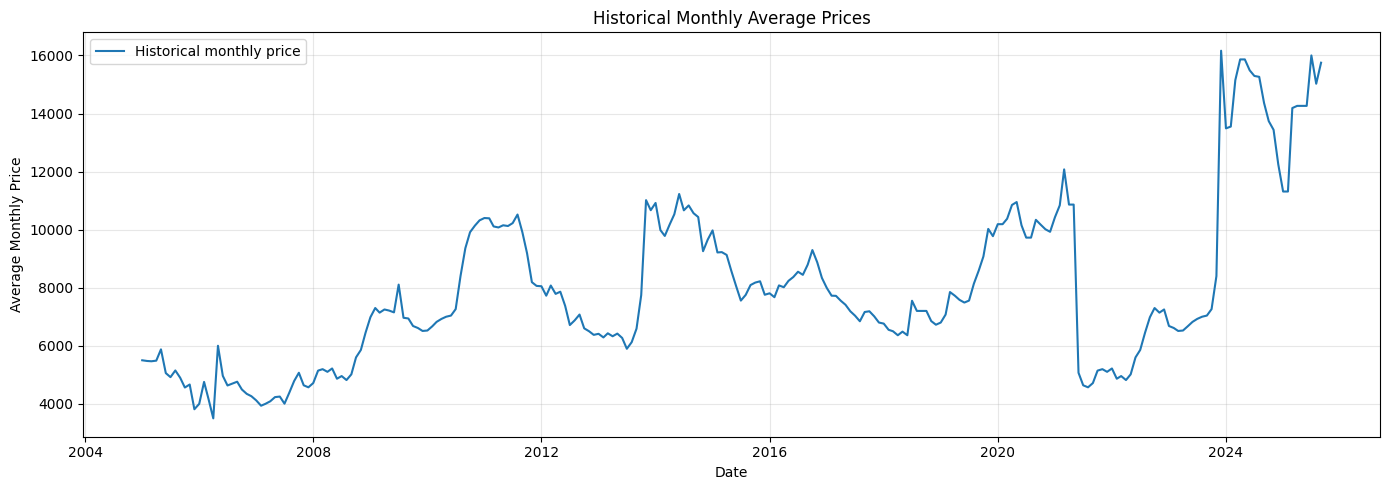

In [24]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 5))

plt.plot(
    df["date"],
    df["avg_monthly_price"],
    label="Historical monthly price"
)

plt.title("Historical Monthly Average Prices")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
print(
    "Zero or negative prices:",
    (df["avg_monthly_price"] <= 0).sum()
)

Zero or negative prices: 0


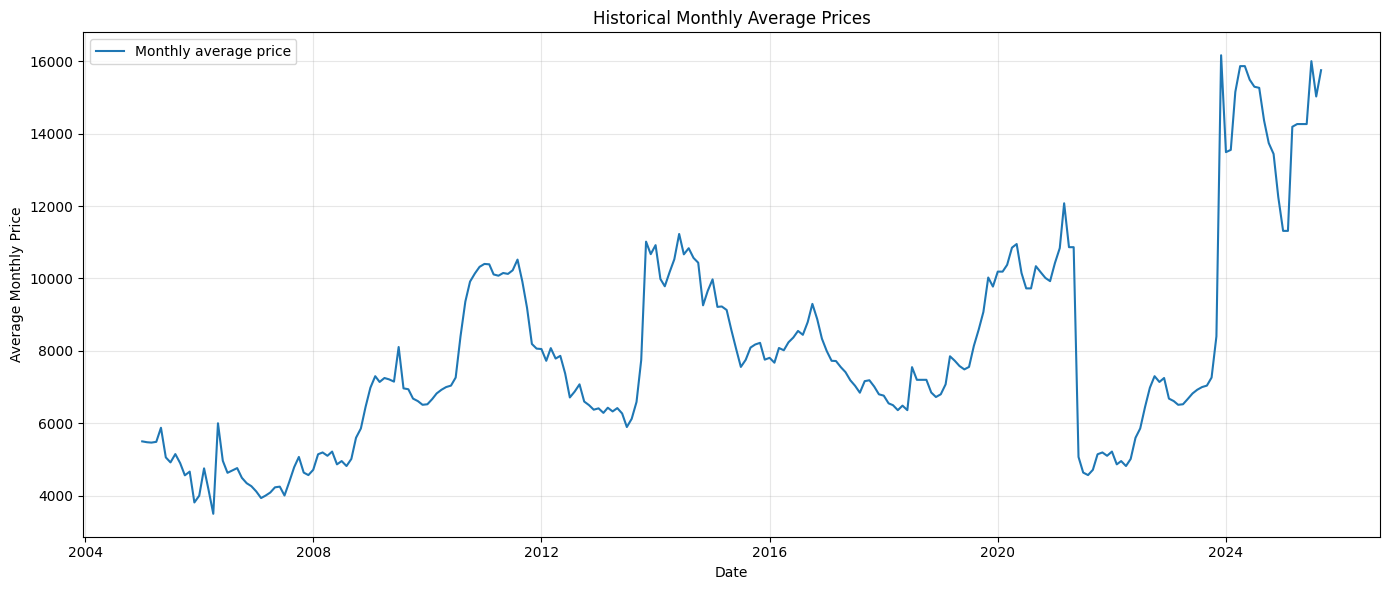

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df["avg_monthly_price"],
    linewidth=1.5,
    label="Monthly average price"
)

plt.title("Historical Monthly Average Prices")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
print(df["avg_monthly_price"].describe())

count      249.000000
mean      7918.891566
std       2804.992684
min       3500.000000
25%       6123.000000
50%       7250.000000
75%       9783.000000
max      16163.000000
Name: avg_monthly_price, dtype: float64


In [28]:
# Calculate average price for each calendar year
yearly_avg = (
    df.set_index("date")["avg_monthly_price"]
      .resample("YE")
      .mean()
)

print(yearly_avg)

date
2005-12-31     5072.500000
2006-12-31     4548.750000
2007-12-31     4339.916667
2008-12-31     5244.500000
2009-12-31     7070.666667
2010-12-31     8031.250000
2011-12-31     9778.833333
2012-12-31     7251.000000
2013-12-31     7181.916667
2014-12-31    10335.916667
2015-12-31     8477.000000
2016-12-31     8372.833333
2017-12-31     7302.666667
2018-12-31     6812.416667
2019-12-31     8139.666667
2020-12-31    10216.833333
2021-12-31     7458.000000
2022-12-31     5954.333333
2023-12-31     7717.500000
2024-12-31    14479.000000
2025-12-31    14042.000000
Freq: YE-DEC, Name: avg_monthly_price, dtype: float64


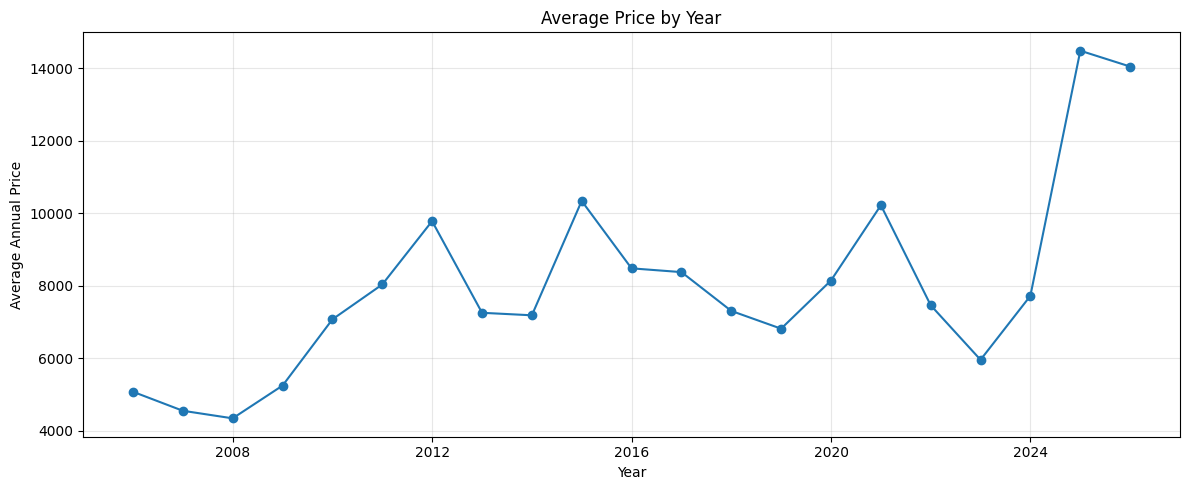

In [29]:
plt.figure(figsize=(12, 5))

plt.plot(
    yearly_avg.index,
    yearly_avg.values,
    marker="o"
)

plt.title("Average Price by Year")
plt.xlabel("Year")
plt.ylabel("Average Annual Price")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
monthly_avg = (
    df.groupby(df["date"].dt.month)["avg_monthly_price"]
      .mean()
)

print(monthly_avg)

date
1     7822.476190
2     7774.666667
3     8086.857143
4     8032.428571
5     8210.238095
6     7770.190476
7     7812.666667
8     7865.523810
9     8044.380952
10    7741.950000
11    7819.250000
12    8038.600000
Name: avg_monthly_price, dtype: float64


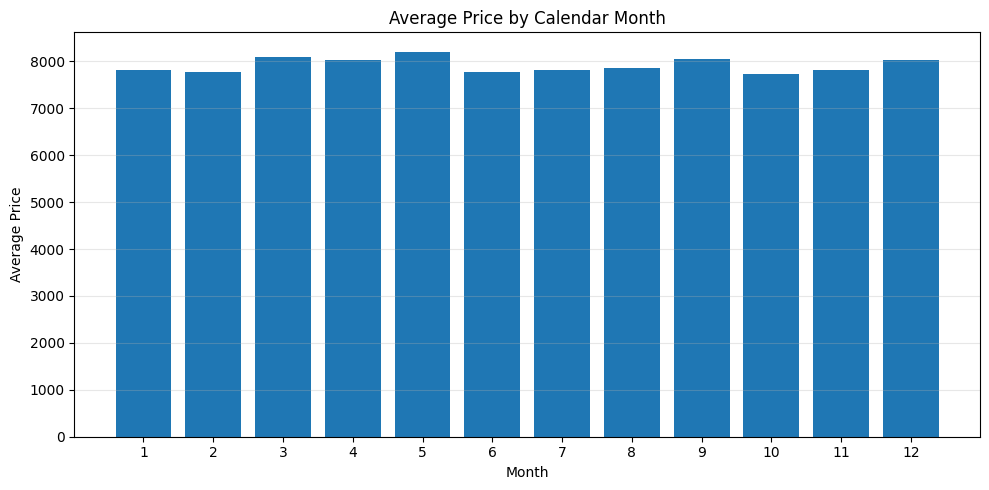

In [31]:
plt.figure(figsize=(10, 5))

plt.bar(
    monthly_avg.index,
    monthly_avg.values
)

plt.title("Average Price by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Price")
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

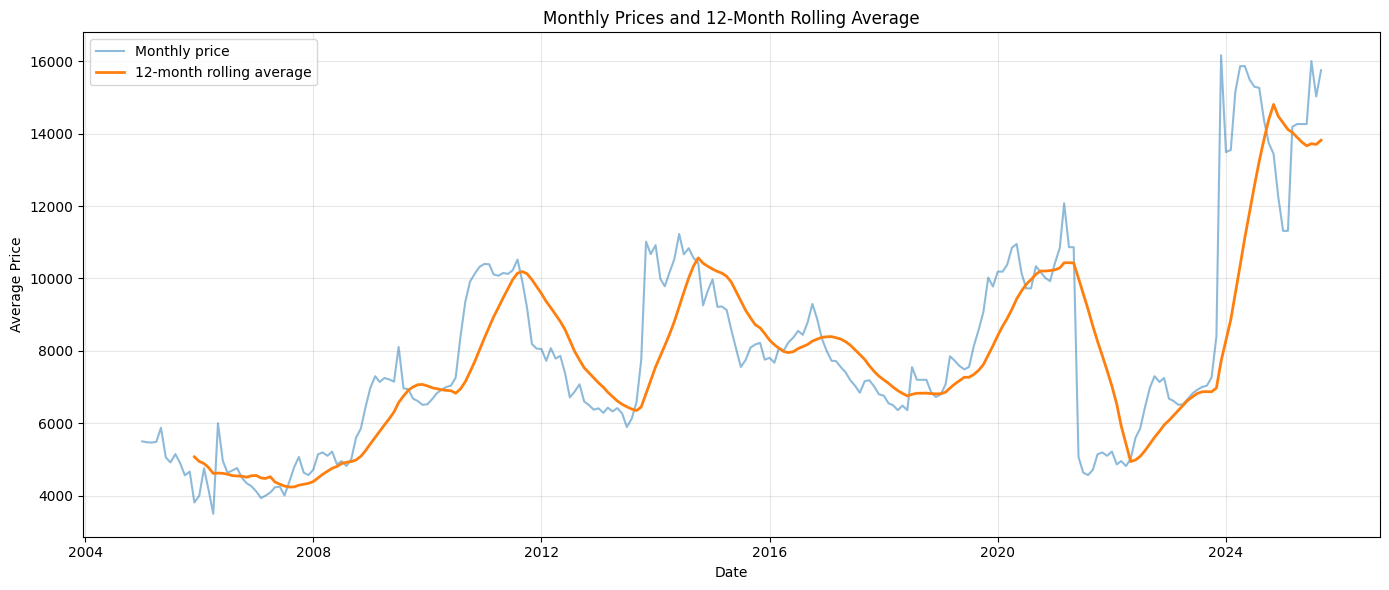

In [32]:
df["rolling_12_month_avg"] = (
    df["avg_monthly_price"]
      .rolling(window=12)
      .mean()
)

plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df["avg_monthly_price"],
    alpha=0.5,
    label="Monthly price"
)

plt.plot(
    df["date"],
    df["rolling_12_month_avg"],
    linewidth=2,
    label="12-month rolling average"
)

plt.title("Monthly Prices and 12-Month Rolling Average")
plt.xlabel("Date")
plt.ylabel("Average Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
import numpy as np
import pandas as pd
df["date"] = pd.to_datetime(df["date"])
series = (
    df.set_index("date")["avg_monthly_price"]
      .asfreq("MS")
)
train = series.iloc[:-24]
test = series.iloc[-24:]
print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Training ends:", train.index[-1])
print("Testing starts:", test.index[0])
print("Testing ends:", test.index[-1])

Training observations: 225
Testing observations: 24
Training ends: 2023-09-01 00:00:00
Testing starts: 2023-10-01 00:00:00
Testing ends: 2025-09-01 00:00:00


In [34]:
# Store each model's test predictions
predictions = {}

# 1. Naive forecast
predictions["Naive"] = np.repeat(
    train.iloc[-1],
    len(test)
)

# 2. Seasonal naive forecast
predictions["Seasonal Naive"] = np.tile(
    train.iloc[-12:].values,
    2
)

# 3. Holt's linear trend
holt_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal=None,
    initialization_method="estimated"
).fit()

predictions["Holt Linear"] = (
    holt_model.forecast(len(test)).values
)

# 4. Holt-Winters additive seasonal model
hw_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
).fit()

predictions["Holt-Winters"] = (
    hw_model.forecast(len(test)).values
)

# 5. SARIMA
sarima_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

predictions["SARIMA"] = (
    sarima_model.forecast(len(test)).values
)

print("All candidate forecasts generated.")

All candidate forecasts generated.


In [35]:
results = []

for name, pred in predictions.items():
    mae = mean_absolute_error(
        test.values, pred
    )

    rmse = np.sqrt(
        mean_squared_error(test.values, pred)
    )

    mape = np.mean(
        np.abs((test.values - pred) / test.values)
    ) * 100

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "MAE"
).reset_index(drop=True)

print(results_df.round(2))

            Model      MAE     RMSE  MAPE (%)
0          SARIMA  6670.71  7052.16     46.18
1    Holt-Winters  6674.28  7059.63     46.18
2     Holt Linear  6719.50  7081.90     46.61
3           Naive  6791.29  7153.85     47.12
4  Seasonal Naive  6961.46  7340.04     48.26


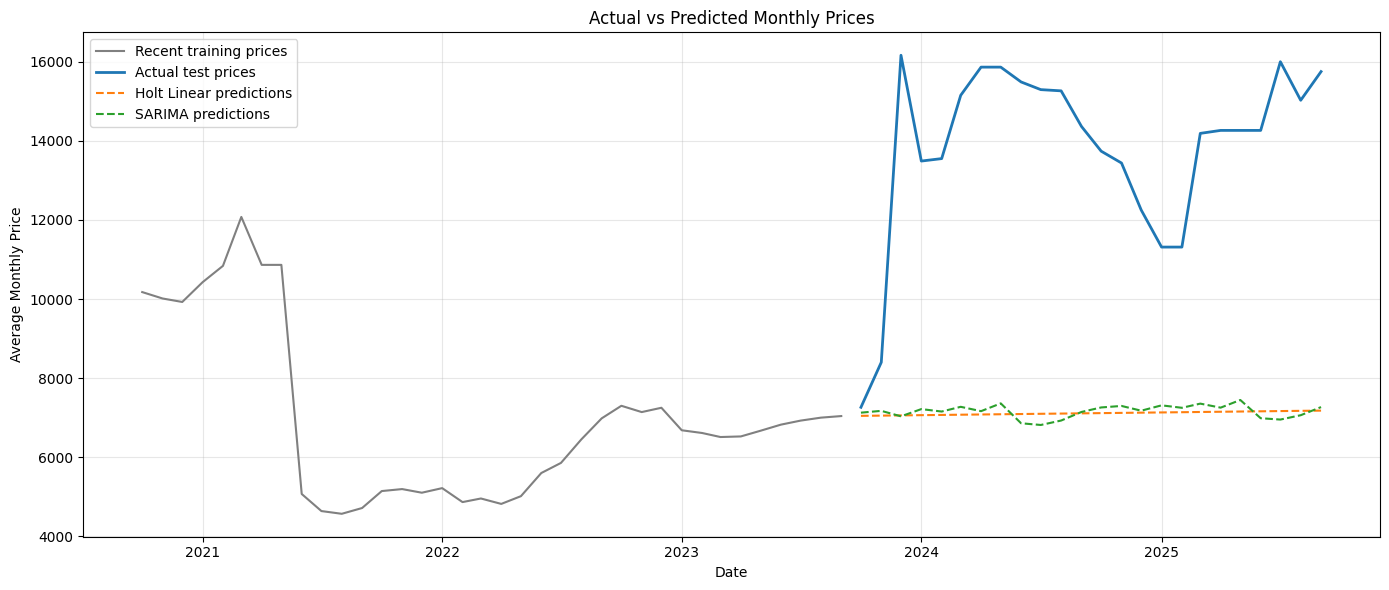

In [36]:
plt.figure(figsize=(14, 6))

plt.plot(
    train.index[-36:],
    train.iloc[-36:],
    label="Recent training prices",
    color="gray"
)

plt.plot(
    test.index,
    test.values,
    label="Actual test prices",
    linewidth=2
)

plt.plot(
    test.index,
    predictions["Holt Linear"],
    label="Holt Linear predictions",
    linestyle="--"
)

plt.plot(
    test.index,
    predictions["SARIMA"],
    label="SARIMA predictions",
    linestyle="--"
)

plt.title("Actual vs Predicted Monthly Prices")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
import warnings
import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Three historical forecast origins
origins = [213, 225, 237]

validation_results = []

for origin in origins:
    train_fold = series.iloc[:origin]
    test_fold = series.iloc[origin:origin + 12]

    forecasts = {}

    # 1. Naive baseline
    forecasts["Naive"] = np.repeat(
        train_fold.iloc[-1], 12
    )

    # 2. Seasonal naive baseline
    forecasts["Seasonal Naive"] = (
        train_fold.iloc[-12:].values
    )

    # 3. Holt's linear trend
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        holt = ExponentialSmoothing(
            train_fold,
            trend="add",
            initialization_method="estimated"
        ).fit()

    forecasts["Holt Linear"] = (
        holt.forecast(12).values
    )

    # 4. Holt-Winters with annual seasonality
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        hw = ExponentialSmoothing(
            train_fold,
            trend="add",
            seasonal="add",
            seasonal_periods=12,
            initialization_method="estimated"
        ).fit()

    forecasts["Holt-Winters"] = (
        hw.forecast(12).values
    )

    # 5. Alternative SARIMA configuration
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        sarima = SARIMAX(
            train_fold,
            order=(0, 1, 1),
            seasonal_order=(0, 1, 1, 12),
            enforce_stationarity=False,
            enforce_invertibility=False
        ).fit(disp=False, maxiter=300)

    forecasts["SARIMA"] = (
        sarima.forecast(12).values
    )

    # Evaluate each model on this fold
    for model_name, forecast in forecasts.items():
        actual = test_fold.values

        validation_results.append({
            "Period": str(test_fold.index[0].date()),
            "Model": model_name,
            "MAE": mean_absolute_error(actual, forecast),
            "RMSE": np.sqrt(
                mean_squared_error(actual, forecast)
            ),
            "MAPE (%)": np.mean(
                np.abs((actual - forecast) / actual)
            ) * 100
        })

# Detailed results for every validation period
validation_df = pd.DataFrame(validation_results)

print(validation_df.round(2).to_string(index=False))

# Average results across the three periods
summary = (
    validation_df.groupby("Model")[
        ["MAE", "RMSE", "MAPE (%)"]
    ]
    .mean()
    .sort_values("MAE")
)

print("\nAverage walk-forward performance:")
print(summary.round(2))

    Period          Model     MAE    RMSE  MAPE (%)
2022-10-01          Naive  245.83  286.87      3.63
2022-10-01 Seasonal Naive 1439.58 1561.27     20.97
2022-10-01    Holt Linear  265.06  308.22      3.92
2022-10-01   Holt-Winters  318.76  401.87      4.74
2022-10-01         SARIMA  326.49  424.85      4.88
2023-10-01          Naive 6805.58 7367.09     45.81
2023-10-01 Seasonal Naive 6978.92 7576.84     46.83
2023-10-01    Holt Linear 6768.25 7327.70     45.55
2023-10-01   Holt-Winters 6740.52 7325.92     45.21
2023-10-01         SARIMA 6736.15 7314.81     45.22
2024-10-01          Naive 1160.33 1565.74      9.12
2024-10-01 Seasonal Naive 2296.42 2921.06     17.35
2024-10-01    Holt Linear 1212.39 1603.09      9.62
2024-10-01   Holt-Winters 1240.09 1614.87      9.85
2024-10-01         SARIMA 1707.73 2143.92     13.52

Average walk-forward performance:
                    MAE     RMSE  MAPE (%)
Model                                     
Naive           2737.25  3073.23     19.52
Holt

In [38]:
# Fit Holt Linear using all available observations
final_holt = ExponentialSmoothing(
    series,
    trend="add",
    initialization_method="estimated"
).fit()

# Forecast the next 12 months
holt_forecast = final_holt.forecast(12)

# Naive forecast: repeat the last observed price
naive_forecast = pd.Series(
    [series.iloc[-1]] * 12,
    index=holt_forecast.index
)

# Create forecast table
forecast_df = pd.DataFrame({
    "Date": holt_forecast.index,
    "Naive Forecast": naive_forecast.values,
    "Holt Linear Forecast": holt_forecast.values
})

print(forecast_df.round(2).to_string(index=False))

      Date  Naive Forecast  Holt Linear Forecast
2025-10-01           15750              15770.31
2025-11-01           15750              15810.45
2025-12-01           15750              15850.59
2026-01-01           15750              15890.73
2026-02-01           15750              15930.88
2026-03-01           15750              15971.02
2026-04-01           15750              16011.16
2026-05-01           15750              16051.30
2026-06-01           15750              16091.44
2026-07-01           15750              16131.58
2026-08-01           15750              16171.73
2026-09-01           15750              16211.87


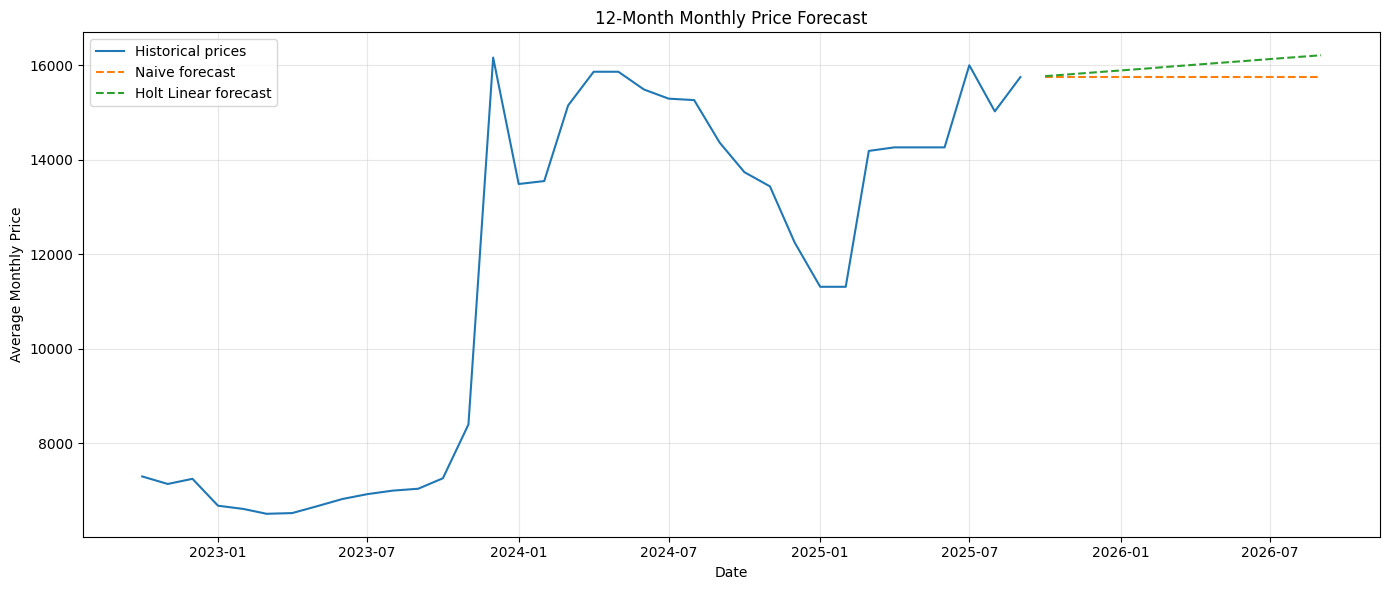

In [39]:
plt.figure(figsize=(14, 6))

# Show the last three years of historical data
plt.plot(
    series.index[-36:],
    series.iloc[-36:],
    label="Historical prices"
)

plt.plot(
    forecast_df["Date"],
    forecast_df["Naive Forecast"],
    linestyle="--",
    label="Naive forecast"
)

plt.plot(
    forecast_df["Date"],
    forecast_df["Holt Linear Forecast"],
    linestyle="--",
    label="Holt Linear forecast"
)

plt.title("12-Month Monthly Price Forecast")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [40]:
import joblib

# Train the selected model using all available historical data
final_holt = ExponentialSmoothing(
    series,
    trend="add",
    initialization_method="estimated"
).fit()

# Save the trained model
joblib.dump(final_holt, "price_forecast_model.joblib")

print("Model saved successfully!")

Model saved successfully!


In [41]:
pip install fastapi uvicorn joblib pandas statsmodels

In [42]:
from google.colab import files

files.download("price_forecast_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:
import os

print(os.path.exists("price_forecast_model.joblib"))

True


In [44]:
import os

print(os.listdir())
print(os.path.exists("price_forecast_model.joblib"))

['.config', 'price_forecast_model.joblib', 'price_data.csv', 'drive', 'sample_data']
True
